In [1]:
# CONFIGURATION
train_device = 'Halle_1'
test_placement = 'start'      # Options: 'start', 'middle', 'end', 'monthly'
USE_SAVED_MODELS = True     

In [2]:
# IMPORT ALL DATA
import os
import pandas as pd

base_path = "../PreprocessedFiles/"
target_file_name = "average_data_all_files.csv"

device_data = {}  # dictionary to store dataframes per device

# os.walk recursively traverses the directory tree
for root, dirs, files in os.walk(base_path):
    if target_file_name in files:
        # Use the name of the folder where the file was found as the device key
        device_name = os.path.basename(root)
        file_path = os.path.join(root, target_file_name)
        
        # Load the single file
        device_data[device_name] = pd.read_csv(file_path)
        print(f"Loaded: {device_name}")

# Print results
for name, df in device_data.items():
    print(f"\nDevice: {name}")
    print(df.info())

Loaded: Halle_1
Loaded: Halle_2
Loaded: Ukkel_1
Loaded: Ukkel_2
Loaded: Ukkel_3

Device: Halle_1
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1694 entries, 0 to 1693
Data columns (total 24 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1694 non-null   int64  
 1   UTC               1694 non-null   int64  
 2   TIMESTAMP         1694 non-null   object 
 3   T_IRCELINE        1694 non-null   object 
 4   Ozon_value(mV)    1694 non-null   float64
 5   NO2_value(mV)     1694 non-null   float64
 6   PM10.0_AVG_PPM    1694 non-null   float64
 7   PM1.0_AVG_PPM     1694 non-null   float64
 8   PM2.5_AVG_PPM     1694 non-null   float64
 9   CO2(ppm)          1694 non-null   float64
 10  CO_value(mV)      1694 non-null   float64
 11  BME68X_PRES(hPa)  1694 non-null   float64
 12  BME68X_HUM(%RH)   1694 non-null   float64
 13  BME68X_TEMP(*C)   1694 non-null   float64
 14  BME68X_VOC(kOhm)  1694 non-null   float

In [3]:
# # PLOT ORIGINAL DATA VS REF
# import matplotlib.pyplot as plt

# df = device_data['Halle_1']

# df['TIMESTAMP'] = pd.to_datetime(df['TIMESTAMP'], errors='coerce')
# df = df[df['TIMESTAMP'] >= '2025-12-01']
# df = df.sort_values('TIMESTAMP')
# df = df.dropna(subset=['TIMESTAMP'])

# # 1. Setup the figure with 3 subplots
# fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(36, 18), sharex=True)

# # 2. Plot Ozone (Sensor vs Ref)
# ax1.plot(df['TIMESTAMP'], df['Ozon_value(mV)'], label='Ozone Sensor', color='blue', alpha=0.7)
# ax1.plot(df['TIMESTAMP'], df['Ozon_ref(mV)'], label='Ozone Ref', color='darkblue', linestyle='--')
# ax1.set_ylabel('Ozone (mV)')
# ax1.legend()
# ax1.set_title('Ozone Comparison')

# # 3. Plot NO2 (Sensor vs Ref)
# ax2.plot(df['TIMESTAMP'], df['NO2_value(mV)'], label='NO2 Sensor', color='red', alpha=0.7)
# ax2.plot(df['TIMESTAMP'], df['NO2_ref(mV)'], label='NO2 Ref', color='darkred', linestyle='--')
# ax2.set_ylabel('NO2 (mV)')
# ax2.legend()
# ax2.set_title('NO2 Comparison')

# # 4. Plot PM10 (Sensor vs Ref)
# ax3.plot(df['TIMESTAMP'], df['PM10.0_AVG_PPM'], label='PM10 Sensor', color='green', alpha=0.7)
# ax3.plot(df['TIMESTAMP'], df['PM10_ref(PPM)'], label='PM10 Ref', color='darkgreen', linestyle='--')
# ax3.set_ylabel('PM10 (PPM)')
# ax3.legend()
# ax3.set_title('PM10 Comparison')

# # 4. Plot PM2.5 (Sensor vs Ref)
# ax4.plot(df['TIMESTAMP'], df['PM2.5_AVG_PPM'], label='PM2.5 Sensor', color='yellow', alpha=0.7)
# ax4.plot(df['TIMESTAMP'], df['PM2.5_ref(PPM)'], label='PM2.5 Ref', color='gold', linestyle='--')
# ax4.set_ylabel('PM2.5 (PPM)')
# ax4.legend()
# ax4.set_title('PM2.5 Comparison')

# plt.xlabel('Time')
# plt.xticks(rotation=45)
# plt.tight_layout()
# # plt.savefig("../GeneratedOutput/Ukkel_2/average_data_plot_all_files.pdf")

# plt.show()

In [4]:
# INITIALIZE RESULTS MANAGER
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
import joblib
import os

class CalibrationResultsManager:
    def __init__(self):
        # Master DataFrame for all scalar metrics. Added 'Seed' column.
        self.metrics_df = pd.DataFrame(columns=[
            'Evaluation_Type',  # 'Source' or 'Transfer'
            'Source_Device',    # e.g., 'Halle_1'
            'Target_Device',    # e.g., 'Ukkel_1' (same as source for 'Source' type)
            'Sensor',           # 'O3', 'NO2', 'PM10', 'PM2.5'
            'Model',            # 'Raw', 'Linear', 'ElasticNet', 'RandomForest', 'GradientBoosting', 'DANN'
            'MAE', 'NMAE', 'RMSE', 'R2', 'CTR', 'Seed'
        ])
        
        # Dictionary to store actual time-series arrays for plotting
        self.predictions = {}

    def add_metric(self, eval_type, source_dev, target_dev, sensor, model, mae, nmae, rmse, r2, seed=0):
        """Adds a row to the metrics database and automatically computes CTR based on the specific seed."""
        ctr = np.nan
        
        # If this is a transfer evaluation, fetch the baseline source MAE for this model/sensor AND SEED
        if eval_type == 'Transfer' and source_dev != target_dev and model != 'Raw':
            source_match = self.metrics_df[
                (self.metrics_df['Evaluation_Type'] == 'Source') &
                (self.metrics_df['Source_Device'] == source_dev) &
                (self.metrics_df['Sensor'] == sensor) &
                (self.metrics_df['Model'] == model) &
                (self.metrics_df['Seed'] == seed) 
            ]
            if not source_match.empty:
                source_mae = source_match['MAE'].values[0]
                ctr = source_mae / mae if mae != 0 else np.nan

        # Append new record
        new_row = pd.DataFrame([{
            'Evaluation_Type': eval_type, 'Source_Device': source_dev, 'Target_Device': target_dev,
            'Sensor': sensor, 'Model': model, 'MAE': mae, 'NMAE': nmae, 'RMSE': rmse, 'R2': r2, 
            'CTR': ctr, 'Seed': seed
        }])
        
        # pd.concat is preferred over append in modern Pandas
        if not new_row.isna().all(axis=None):
            self.metrics_df = pd.concat([self.metrics_df, new_row], ignore_index=True)

    def store_predictions(self, key_tuple, timestamps, y_true, y_pred, y_raw):
        """Stores dense arrays for time-series plotting.
        Expected key_tuple format: (eval_type, source_dev, target_dev, sensor, model, seed)
        """
        self.predictions[key_tuple] = {
            'timestamps': timestamps,
            'y_true': y_true,
            'y_pred': y_pred,
            'y_raw': y_raw
        }

    def get_summary_table(self, eval_type='Transfer', metric='MAE'):
        """Generates a pivot table with enforced column order, averaging across seeds."""
        filtered = self.metrics_df[self.metrics_df['Evaluation_Type'] == eval_type]
        
        # The pivot_table automatically averages (aggfunc='mean') the metric across all seeds
        pivot = filtered.pivot_table(
            index=['Source_Device', 'Target_Device', 'Sensor'],
            columns='Model',
            values=metric,
            aggfunc='mean' 
        )
        desired_order = ['Raw', 'Linear', 'ElasticNet', 'RandomForest', 'GradientBoosting', 'DANN']
        existing_order = [col for col in desired_order if col in pivot.columns]
        other_cols = [col for col in pivot.columns if col not in desired_order]
        return pivot[existing_order + other_cols]

# Initialize the manager
results_manager = CalibrationResultsManager()
current_seed = 0

In [5]:
# DATA PREPROCESSING
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import joblib
import os

# Define configurations globally
sensors = {'O3': 'Ozon_ref(mV)', 'NO2': 'NO2_ref(mV)', 'PM10': 'PM10_ref(PPM)', 'PM2.5': 'PM2.5_ref(PPM)'}
raw_map = {'O3': 'Ozon_value(mV)', 'NO2': 'NO2_value(mV)', 'PM10': 'PM10.0_AVG_PPM', 'PM2.5': 'PM2.5_AVG_PPM'}
all_ref = list(sensors.values())

# Sort timestamp, add pm ratios and hour/month, drop unused columns
def preprocess(key, df):
    df = df.copy()
    if 'TIMESTAMP' in df.columns:
        df['TIMESTAMP'] = pd.to_datetime(df['TIMESTAMP'], errors='coerce')
        df = df[df['TIMESTAMP'] >= '2025-12-01']
        if key == 'Halle_1':
            # valid_mask = (df['TIMESTAMP'] <= '2026-01-14') | ((df['TIMESTAMP'] >= '2026-03-01'))  # exclude data where O3 sensor was faulty
            # df = df[valid_mask]
            df = df[df['TIMESTAMP'] <= '2026-03-01'] # optional: exclude summer data
            # df = df[df['TIMESTAMP'] >= '2026-03-29'] # optional: exclude winter data
        elif key == 'Halle_2':
            df = df[df['TIMESTAMP'] <= '2026-03-01'] # optional: exclude summer data
            # df = df[df['TIMESTAMP'] >= '2026-03-29'] # optional: exclude winter data
        df = df.sort_values('TIMESTAMP')
        df['Hour'] = df['TIMESTAMP'].dt.hour
        df['Month'] = df['TIMESTAMP'].dt.month
        df['Hour_sin'] = np.sin(2 * np.pi * df['Hour']/24)
        df['Hour_cos'] = np.cos(2 * np.pi * df['Hour']/24)
        df['Month_sin'] = np.sin(2 * np.pi * df['Month']/12)
        df['Month_cos'] = np.cos(2 * np.pi * df['Month']/12)
    df['PM10_PM2.5_ratio'] = np.where(df['PM2.5_AVG_PPM'] != 0, df['PM10.0_AVG_PPM'] / df['PM2.5_AVG_PPM'], np.nan)
    df['PM2.5_PM1_ratio'] = np.where(df['PM1.0_AVG_PPM'] != 0, df['PM2.5_AVG_PPM'] / df['PM1.0_AVG_PPM'], np.nan)
    df['log_PM10_PM2.5_ratio'] = np.log1p(df['PM10_PM2.5_ratio'])
    df['log_PM2.5_PM1_ratio'] = np.log1p(df['PM2.5_PM1_ratio'])
    df.drop(columns=['Unnamed: 0', 'Hour', 'Month', 'PM10_PM2.5_ratio', 'PM2.5_PM1_ratio'], axis=1, inplace=True, errors='ignore')
    
    df = df.dropna(subset=all_ref)
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    df = df.dropna(subset=numeric_cols)
    cols_to_keep = ['TIMESTAMP'] + list(numeric_cols) if 'TIMESTAMP' in df.columns else list(numeric_cols)
    df = df[cols_to_keep]
    return df

# Execute preprocessing
for key in device_data:
    print(f"Device {key}: Before preprocessing rows = {len(device_data[key])}")
    device_data[key] = preprocess(key, device_data[key])
    print(f"Device {key}: After preprocessing rows = {len(device_data[key])}\n")

Device Halle_1: Before preprocessing rows = 1694
Device Halle_1: After preprocessing rows = 186

Device Halle_2: Before preprocessing rows = 1310
Device Halle_2: After preprocessing rows = 473

Device Ukkel_1: Before preprocessing rows = 117
Device Ukkel_1: After preprocessing rows = 112

Device Ukkel_2: Before preprocessing rows = 144
Device Ukkel_2: After preprocessing rows = 135

Device Ukkel_3: Before preprocessing rows = 525
Device Ukkel_3: After preprocessing rows = 506



In [31]:
# TRAIN/TEST SPLIT
df = device_data[train_device]
timestamps = df['TIMESTAMP']
X = df.drop(columns=all_ref + ['TIMESTAMP'], errors='ignore')
Y = df[all_ref]

save_dir_temp = f"../saved_models_temp/{train_device}/" 
save_dir = f"../saved_models/{train_device}/" 
os.makedirs(save_dir_temp, exist_ok=True)

X.info(), Y.info()

X_base, Y_base, t_base = X, Y, timestamps
total_len = len(X_base)
test_size = int(total_len * 0.2)

if test_placement == 'start':
    X_test, Y_test, t_test = X_base.iloc[:test_size], Y_base.iloc[:test_size], t_base.iloc[:test_size]
    X_train, Y_train = X_base.iloc[test_size:], Y_base.iloc[test_size:]

elif test_placement == 'middle':
    # Derived starting index using integer casting to ensure safe index slicing
    start_idx = int((total_len - test_size) * 0.4)
    end_idx = start_idx + test_size
    
    X_test, Y_test, t_test = X_base.iloc[start_idx:end_idx], Y_base.iloc[start_idx:end_idx], t_base.iloc[start_idx:end_idx]    
    X_train, Y_train = pd.concat([X_base.iloc[:start_idx], X_base.iloc[end_idx:]]), pd.concat([Y_base.iloc[:start_idx], Y_base.iloc[end_idx:]])

elif test_placement == 'end':
    X_test, Y_test, t_test = X_base.iloc[-test_size:], Y_base.iloc[-test_size:], t_base.iloc[-test_size:]   
    X_train, Y_train = X_base.iloc[:-test_size], Y_base.iloc[:-test_size]

elif test_placement == 'monthly':
    train_idx, test_idx = [], []
    # Identify unique months in the dataset
    months = t_base.dt.month.unique()
    
    for m in months:
        # Get positional indices for the current month
        m_indices = np.where(t_base.dt.month == m)[0]
        # Calculate 80% split point for this specific month
        split_point = int(len(m_indices) * 0.8)
        
        train_idx.extend(m_indices[:split_point])
        test_idx.extend(m_indices[split_point:])
        
    X_train, Y_train = X_base.iloc[train_idx], Y_base.iloc[train_idx]
    X_test, Y_test, t_test = X_base.iloc[test_idx], Y_base.iloc[test_idx], t_base.iloc[test_idx]

print(f"\nTest Window Placement:  [{test_placement.upper()}]")
print(f"Row counts:")
print(f"Train (80% of Base): {len(X_train)}")
print(f"Test  (20% of Base): {len(X_test)}")
print(f"Total rows matched inside framework: {len(X_base)}")

<class 'pandas.core.frame.DataFrame'>
Index: 820 entries, 530 to 1691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   UTC                   820 non-null    int64  
 1   Ozon_value(mV)        820 non-null    float64
 2   NO2_value(mV)         820 non-null    float64
 3   PM10.0_AVG_PPM        820 non-null    float64
 4   PM1.0_AVG_PPM         820 non-null    float64
 5   PM2.5_AVG_PPM         820 non-null    float64
 6   CO2(ppm)              820 non-null    float64
 7   CO_value(mV)          820 non-null    float64
 8   BME68X_PRES(hPa)      820 non-null    float64
 9   BME68X_HUM(%RH)       820 non-null    float64
 10  BME68X_TEMP(*C)       820 non-null    float64
 11  BME68X_VOC(kOhm)      820 non-null    float64
 12  Lux                   820 non-null    float64
 13  UVA                   820 non-null    float64
 14  UVB                   820 non-null    float64
 15  UVC                   820

In [32]:
# INITIALIZE AND TRAIN ALL MODELS
import os
import numpy as np
import pandas as pd
import joblib
import itertools
import random 

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, ElasticNet
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import make_scorer, mean_absolute_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.autograd import Function
from torch.utils.data import DataLoader, TensorDataset

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class GradientReversalLayer(Function):
    @staticmethod
    def forward(ctx, x, alpha):
        ctx.alpha = alpha
        return x.view_as(x)

    @staticmethod
    def backward(ctx, grad_output):
        return grad_output.neg() * ctx.alpha, None

class DANN(nn.Module):
    def __init__(self, input_dim, num_domains, dropout_rate=0.2):
        super().__init__()
        self.feature_extractor = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.LayerNorm(128),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(128, 64),
            nn.LayerNorm(64),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )
        self.label_predictor = nn.Sequential(
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
        self.domain_classifier = nn.Sequential(
            nn.Linear(64, 32),
            nn.LayerNorm(32),
            nn.ReLU(),
            nn.Linear(32, num_domains)
        )

    def forward(self, x, alpha=1.0):
        features = self.feature_extractor(x)
        label_output = self.label_predictor(features)
        reversed_features = GradientReversalLayer.apply(features, alpha)
        domain_output = self.domain_classifier(reversed_features)
        return label_output, domain_output

# Add DANN as a placeholder in the models dict so it iterates with the rest
models = {
    "Linear": Pipeline([('scaler', StandardScaler()), ('regressor', LinearRegression())]),
    "ElasticNet": Pipeline([('scaler', StandardScaler()), ('en', ElasticNet(alpha=0.1, l1_ratio=0.5))]),
    "RandomForest": Pipeline([('rf', RandomForestRegressor(n_estimators=200, random_state=42))]),
    "GradientBoosting": Pipeline([('gb', GradientBoostingRegressor(random_state=42))]),
    "DANN": None  
}


# TRAIN ALL MODELS 
best_models = {}
tscv = TimeSeriesSplit(n_splits=3)
mae_scorer = make_scorer(mean_absolute_error, greater_is_better=False)

param_grids = {
    "Linear": {},
    "ElasticNet": {"en__alpha": [1, 1e-2, 1e-4, 1e-6], "en__l1_ratio": [1, 1e-2, 1e-4]},
    "RandomForest": {"rf__n_estimators": [20, 60, 100, 200], "rf__max_depth": [3, 5, 8, None]},
    "GradientBoosting": {"gb__min_samples_leaf": [1, 4, 10]},
    "DANN": {"lr": [1e-3, 5e-4], "dropout_rate": [0.2, 0.4]}
}

def set_seed(seed=42):
    """Locks all random seeds for reproducible PyTorch results."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

for model_name, model in models.items():
    best_models[model_name] = {}
    print(f"\n========== {model_name.upper()} ==========")

    for sensor_name, target_col in sensors.items():
        # DANN uses PyTorch state_dict (.pt), Scikit-learn uses joblib
        model_ext = ".pt" if model_name == "DANN" else ".joblib"
        model_path = os.path.join(save_dir, f"{model_name}_{sensor_name}_model{model_ext}")
        scaler_path = os.path.join(save_dir, f"{model_name}_{sensor_name}_scaler.joblib")
        model_path_temp = os.path.join(save_dir_temp, f"{model_name}_{sensor_name}_model{model_ext}")
        scaler_path_temp = os.path.join(save_dir_temp, f"{model_name}_{sensor_name}_scaler.joblib")

        if USE_SAVED_MODELS and os.path.exists(model_path) and os.path.exists(scaler_path):
            print(f"[{sensor_name}] Loading saved model and scaler from disk...")
            if model_name == "DANN":
                best_model = DANN(input_dim=len(X_train.columns), num_domains=len(device_data)).to(device)
                best_model.load_state_dict(torch.load(model_path))
                y_scaler = joblib.load(scaler_path) # For DANN, this is the X-scaler
            else:
                best_model = joblib.load(model_path)
                y_scaler = joblib.load(scaler_path)
            
        else:
            print(f"[{sensor_name}] Training new model...")
            
            # --- DANN SPECIFIC TRAINING LOOP ---
            if model_name == "DANN":
                X_cols = X_train.columns.tolist()
                df_src_clean = pd.concat([X_train, Y_train], axis=1).dropna(subset=X_cols + [target_col])
                X_src = df_src_clean[X_cols].values
                y_src = df_src_clean[target_col].values.reshape(-1, 1)
                domain_src = np.zeros(len(X_src))

                X_tgt_list, domain_tgt_list = [], []
                domain_idx = 1
                for device_name, df_device in device_data.items():
                    if device_name == train_device: continue
                    df_tgt_clean = df_device.dropna(subset=X_cols + [target_col])
                    if len(df_tgt_clean) == 0: continue
                    X_tgt_list.append(df_tgt_clean[X_cols].values)
                    domain_tgt_list.append(np.ones(len(df_tgt_clean)) * domain_idx)
                    domain_idx += 1

                X_tgt = np.concatenate(X_tgt_list) if X_tgt_list else np.empty((0, len(X_cols)))
                domain_tgt = np.concatenate(domain_tgt_list) if domain_tgt_list else np.empty((0,))

                scaler = StandardScaler()
                X_src_scaled = scaler.fit_transform(X_src)
                X_tgt_scaled = scaler.transform(X_tgt) if len(X_tgt) > 0 else X_tgt

                # Generate hyperparameter combinations for DANN
                param_grid = param_grids.get("DANN", {"lr": [1e-3], "dropout_rate": [0.2]})
                keys, values = zip(*param_grid.items())
                dann_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]
                
                best_dann_model = None
                best_mae = float('inf')
                best_params = None

                print(f"  Running DANN Grid Search ({len(dann_combinations)} combinations)...")

                for params in dann_combinations:
                    set_seed(42) # Ensure reproducible results for every run
                    
                    lr = params.get('lr', 1e-3)
                    dropout = params.get('dropout_rate', 0.2)
                    
                    src_loader = DataLoader(TensorDataset(torch.tensor(X_src_scaled, dtype=torch.float32).to(device), 
                                                          torch.tensor(y_src, dtype=torch.float32).to(device), 
                                                          torch.tensor(domain_src, dtype=torch.long).to(device)), batch_size=128, shuffle=True)
                    tgt_loader = DataLoader(TensorDataset(torch.tensor(X_tgt_scaled, dtype=torch.float32).to(device), 
                                                          torch.tensor(domain_tgt, dtype=torch.long).to(device)), batch_size=128, shuffle=True)

                    dann_model = DANN(input_dim=len(X_cols), num_domains=len(device_data), dropout_rate=dropout).to(device)
                    optimizer = optim.Adam(dann_model.parameters(), lr=lr, weight_decay=1e-4)
                    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=100)
                    criterion_label = nn.L1Loss()
                    criterion_domain = nn.CrossEntropyLoss()

                    len_dataloader = max(len(src_loader), len(tgt_loader))
                    dann_model.train()

                    for epoch in range(100): 
                        src_iter, tgt_iter = iter(src_loader), iter(tgt_loader)
                        for j in range(len_dataloader):
                            try: src_x, src_y, src_d = next(src_iter)
                            except StopIteration: src_iter = iter(src_loader); src_x, src_y, src_d = next(src_iter)
                            try: tgt_x, tgt_d = next(tgt_iter)
                            except StopIteration: tgt_iter = iter(tgt_loader); tgt_x, tgt_d = next(tgt_iter)

                            p = float(epoch * len_dataloader + j) / (100 * len_dataloader)
                            alpha = 2. / (1. + np.exp(-10 * p)) - 1.

                            src_label, src_domain = dann_model(src_x, alpha)
                            _, tgt_domain = dann_model(tgt_x, alpha)

                            loss = criterion_label(src_label, src_y) + (criterion_domain(src_domain, src_d) + criterion_domain(tgt_domain, tgt_d))
                            optimizer.zero_grad()
                            loss.backward()
                            torch.nn.utils.clip_grad_norm_(dann_model.parameters(), max_norm=1.0)
                            optimizer.step()
                        scheduler.step()
                        
                    # Evaluate this combination on the source training data to find the best fit
                    dann_model.eval()
                    with torch.no_grad():
                        preds, _ = dann_model(torch.tensor(X_src_scaled, dtype=torch.float32).to(device))
                        current_mae = mean_absolute_error(y_src, preds.cpu().numpy().ravel())
                    
                    if current_mae < best_mae:
                        best_mae = current_mae
                        best_dann_model = dann_model
                        best_params = params

                print(f"  Best DANN Params: {best_params} | Best Source MAE: {best_mae:.3f}")
                
                best_model = best_dann_model
                y_scaler = scaler 
                
                torch.save(best_model.state_dict(), model_path_temp)
                joblib.dump(y_scaler, scaler_path_temp)
                
            # --- CLASSICAL MODELS LOOP ---
            else:
                y_train = Y_train[target_col]
                y_scaler = StandardScaler()
                y_train_scaled = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()
                param_grid = param_grids.get(model_name, {})

                if param_grid:
                    grid = GridSearchCV(model, param_grid, cv=tscv, scoring=mae_scorer, n_jobs=-1)
                    grid.fit(X_train, y_train_scaled)
                    best_model = grid.best_estimator_
                else:
                    model.fit(X_train, y_train_scaled)
                    best_model = model

                joblib.dump(best_model, model_path_temp)
                joblib.dump(y_scaler, scaler_path_temp)

        best_models[model_name][sensor_name] = (best_model, y_scaler)

        # --- FEATURE IMPORTANCE / BEST PARAMS SECTION ---
        if model_name == "DANN":
            # Log DANN's selected parameters from Grid Search
            if 'best_params' in locals() and best_params:
                print(f"   Best Params: {best_params}")

            # Ensure X_src and y_src exist even if the model was loaded from disk
            X_cols = X_train.columns.tolist()
            df_src_clean = pd.concat([X_train, Y_train], axis=1).dropna(subset=X_cols + [target_col])
            X_src = df_src_clean[X_cols].values
            y_src = df_src_clean[target_col].values.reshape(-1, 1)
            
            # Measures how much MSE increases when a feature is shuffled
            best_model.eval()
            X_tensor = torch.tensor(y_scaler.transform(X_src), dtype=torch.float32).to(device)
            with torch.no_grad():
                base_preds, _ = best_model(X_tensor)
                base_mse = np.mean((y_src - base_preds.cpu().numpy()) ** 2)
            
            importances = []
            feature_names = X_train.columns
            for col_idx in range(X_src.shape[1]):
                X_permuted = X_src.copy()
                np.random.shuffle(X_permuted[:, col_idx])
                X_permuted_tensor = torch.tensor(y_scaler.transform(X_permuted), dtype=torch.float32).to(device)
                with torch.no_grad():
                    perm_preds, _ = best_model(X_permuted_tensor)
                    perm_mse = np.mean((y_src - perm_preds.cpu().numpy()) ** 2)
                importances.append(perm_mse - base_mse)
            
            importances = np.array(importances)
            indices = np.argsort(importances)[-5:][::-1]  # Top 5 features
            print(f"   Top Predictors (Permutation): {', '.join([f'{feature_names[i]} ({importances[i]:.4f})' for i in indices])}")

        else:
            # Classical Models (Scikit-Learn Pipeline)
            step_name = list(best_model.named_steps.keys())[-1]
            regressor = best_model.named_steps[step_name]
            feature_names = X_train.columns

            param_grid = param_grids.get(model_name, {})
            if param_grid:
                active_params = {p.split("__")[-1]: v for p, v in regressor.get_params().items() if p.split("__")[-1] in [k.split("__")[-1] for k in param_grid]}
                print(f"   Best Params: {active_params}")

            if hasattr(regressor, 'coef_'):
                coefs = regressor.coef_
                indices = np.argsort(coefs)
                print(f"   Top Positive: {', '.join([f'{feature_names[i]} ({coefs[i]:.3f})' for i in indices[-3:][::-1]])}")
                print(f"   Top Negative: {', '.join([f'{feature_names[i]} ({coefs[i]:.3f})' for i in indices[:3]])}")
                
            elif hasattr(regressor, 'feature_importances_'):
                importances = regressor.feature_importances_
                indices = np.argsort(importances)[-10:][::-1]
                print(f"   Top Predictors: {', '.join([f'{feature_names[i]} ({importances[i]:.3f})' for i in indices])}")
        print("-" * 30)


========== LINEAR ==========
[O3] Loading saved model and scaler from disk...
   Top Positive: PM2.5_AVG_PPM (0.499), UTC (0.331), NO2_value(mV) (0.181)
   Top Negative: BME68X_HUM(%RH) (-0.536), PM10.0_AVG_PPM (-0.514), BME68X_VOC(kOhm) (-0.342)
------------------------------
[NO2] Loading saved model and scaler from disk...
   Top Positive: UTC (0.548), PM2.5_AVG_PPM (0.472), Ozon_value(mV) (0.332)
   Top Negative: PM10.0_AVG_PPM (-0.525), BME68X_VOC(kOhm) (-0.395), NO2_value(mV) (-0.288)
------------------------------
[PM10] Loading saved model and scaler from disk...
   Top Positive: PM10.0_AVG_PPM (1.231), PM1.0_AVG_PPM (0.706), UTC (0.363)
   Top Negative: PM2.5_AVG_PPM (-1.794), BME68X_VOC(kOhm) (-0.339), BME68X_HUM(%RH) (-0.286)
------------------------------
[PM2.5] Loading saved model and scaler from disk...
   Top Positive: PM10.0_AVG_PPM (1.794), PM1.0_AVG_PPM (0.804), BME68X_TEMP(*C) (0.429)
   Top Negative: PM2.5_AVG_PPM (-2.411), BME68X_VOC(kOhm) (-0.198), BME68X_PRES(h

In [33]:
# UNIFIED EVALUATION (SOURCE AND TARGET)
# =====================================================================
print("\n========== EVALUATING ALL MODELS (INC. DANN) ==========")

def compute_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    y_range = (np.max(y_true) - np.min(y_true))
    nmae = (mae / y_range * 100) if y_range != 0 else 0
    # Assuming root_mean_squared_error is properly imported
    rmse = root_mean_squared_error(y_true, y_pred) 
    r2 = r2_score(y_true, y_pred)
    return mae, nmae, rmse, r2

X_cols = X_train.columns.tolist()
current_seed+=1

for sensor_name, target_col in sensors.items():
    print(f"\n\n ======================================= {sensor_name} =======================================")
    
    # -------------------------------------------------------------
    # 1. EVALUATE SOURCE DOMAIN
    # -------------------------------------------------------------
    df_src_eval = pd.concat([X_test, Y_test], axis=1)
    df_src_eval['TIMESTAMP'] = t_test
    df_src_eval = df_src_eval.dropna(subset=X_cols + [target_col])
    
    x_src_test = df_src_eval[X_cols]
    y_src_test = df_src_eval[target_col].values
    t_src_test = df_src_eval['TIMESTAMP'].values
    y_raw_src = df_src_eval[raw_map[sensor_name]].values
    
    for model_name in best_models:
        best_model, scaler = best_models[model_name][sensor_name]
        
        # Diverging Prediction Logic
        if model_name == "DANN":
            best_model.eval()
            with torch.no_grad():
                preds, _ = best_model(torch.tensor(scaler.transform(x_src_test.values), dtype=torch.float32).to(device))
                y_pred = preds.cpu().numpy().ravel()
        else:
            y_pred_scaled = best_model.predict(x_src_test)
            y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
        
        mae, nmae, rmse, r2 = compute_metrics(y_src_test, y_pred)
        
        # Log baseline once per sensor
        if model_name == list(best_models.keys())[0]:
            raw_mae, raw_nmae, raw_rmse, raw_r2 = compute_metrics(y_src_test, y_raw_src)
            results_manager.add_metric('Source', train_device, train_device, sensor_name, 'Raw', raw_mae, raw_nmae, raw_rmse, raw_r2, seed=current_seed)
            results_manager.store_predictions(('Source', train_device, train_device, sensor_name, 'Raw'), t_src_test, y_src_test, y_raw_src, y_raw_src)

        improv = ((raw_mae - mae)/raw_mae) * 100 if raw_mae != 0 else 0
        results_manager.add_metric('Source', train_device, train_device, sensor_name, model_name, mae, nmae, rmse, r2, seed=current_seed)
        results_manager.store_predictions(('Source', train_device, train_device, sensor_name, model_name), t_src_test, y_src_test, y_pred, y_raw_src)
        print(f"Source ({train_device}) | {model_name:15} | MAE={mae:.3f} (Raw: {raw_mae:.3f}) | R2={r2:.3f} | Improvement={improv:+.2f}%")

    # -------------------------------------------------------------
    # 2. EVALUATE TARGET DOMAINS
    # -------------------------------------------------------------
    for device_name, df_device in device_data.items():
        if device_name == train_device: continue
        
        df_tgt_clean = df_device.dropna(subset=X_cols + [target_col])
        if len(df_tgt_clean) == 0: continue
        
        x_tgt = df_tgt_clean[X_cols]
        y_tgt = df_tgt_clean[target_col].values
        t_tgt = df_tgt_clean['TIMESTAMP'].values
        y_raw_tgt = df_tgt_clean[raw_map[sensor_name]].values

        print("\n")
        for model_name in best_models:
            best_model, scaler = best_models[model_name][sensor_name]
            
            # Diverging Prediction Logic
            if model_name == "DANN":
                best_model.eval()
                with torch.no_grad():
                    preds, _ = best_model(torch.tensor(scaler.transform(x_tgt.values), dtype=torch.float32).to(device))
                    y_pred = preds.cpu().numpy().ravel()
            else:
                y_pred_scaled = best_model.predict(x_tgt)
                y_pred = scaler.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
            
            mae, nmae, rmse, r2 = compute_metrics(y_tgt, y_pred)
            
            # Log baseline once
            if model_name == list(best_models.keys())[0]:
                raw_mae, raw_nmae, raw_rmse, raw_r2 = compute_metrics(y_tgt, y_raw_tgt)
                results_manager.add_metric('Transfer', train_device, device_name, sensor_name, 'Raw', raw_mae, raw_nmae, raw_rmse, raw_r2, seed=current_seed)

            improv = ((raw_mae - mae)/raw_mae) * 100 if raw_mae != 0 else 0
            results_manager.add_metric('Transfer', train_device, device_name, sensor_name, model_name, mae, nmae, rmse, r2, seed=current_seed)
            results_manager.store_predictions(('Transfer', train_device, device_name, sensor_name, model_name), t_tgt, y_tgt, y_pred, y_raw_tgt)
            print(f"Target ({device_name:8}) | {model_name:15} | MAE={mae:.3f} (Raw: {raw_mae:.3f}) | R2={r2:.3f} | Improvement={improv:+.2f}%")


========== EVALUATING ALL MODELS (INC. DANN) ==========


 ======================================= O3 =======================================
Source (Halle_1) | Linear          | MAE=32.320 (Raw: 57.163) | R2=-2.353 | Improvement=+43.46%
Source (Halle_1) | ElasticNet      | MAE=27.661 (Raw: 57.163) | R2=-1.395 | Improvement=+51.61%
Source (Halle_1) | RandomForest    | MAE=11.812 (Raw: 57.163) | R2=0.480 | Improvement=+79.34%
Source (Halle_1) | GradientBoosting | MAE=11.698 (Raw: 57.163) | R2=0.486 | Improvement=+79.54%
Source (Halle_1) | DANN            | MAE=39.497 (Raw: 57.163) | R2=-3.754 | Improvement=+30.90%


Target (Halle_2 ) | Linear          | MAE=39.350 (Raw: 41.473) | R2=-3.098 | Improvement=+5.12%
Target (Halle_2 ) | ElasticNet      | MAE=30.697 (Raw: 41.473) | R2=-1.585 | Improvement=+25.98%
Target (Halle_2 ) | RandomForest    | MAE=18.275 (Raw: 41.473) | R2=0.183 | Improvement=+55.94%
Target (Halle_2 ) | GradientBoosting | MAE=17.984 (Raw: 41.473) | R2=0.182 | Improvemen

C:\Users\kisho\AppData\Local\Temp\ipykernel_11000\2412302148.py:57: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  self.metrics_df = pd.concat([self.metrics_df, new_row], ignore_index=True)


Target (Ukkel_1 ) | RandomForest    | MAE=21.176 (Raw: 16.599) | R2=-0.598 | Improvement=-27.57%
Target (Ukkel_1 ) | GradientBoosting | MAE=24.484 (Raw: 16.599) | R2=-1.031 | Improvement=-47.50%
Target (Ukkel_1 ) | DANN            | MAE=20.947 (Raw: 16.599) | R2=-0.401 | Improvement=-26.19%


Target (Ukkel_2 ) | Linear          | MAE=50.519 (Raw: 16.170) | R2=-8.209 | Improvement=-212.43%
Target (Ukkel_2 ) | ElasticNet      | MAE=34.503 (Raw: 16.170) | R2=-3.516 | Improvement=-113.38%
Target (Ukkel_2 ) | RandomForest    | MAE=19.202 (Raw: 16.170) | R2=-0.793 | Improvement=-18.76%
Target (Ukkel_2 ) | GradientBoosting | MAE=23.441 (Raw: 16.170) | R2=-1.502 | Improvement=-44.97%
Target (Ukkel_2 ) | DANN            | MAE=21.096 (Raw: 16.170) | R2=-0.630 | Improvement=-30.47%


Target (Ukkel_3 ) | Linear          | MAE=53.274 (Raw: 59.583) | R2=-5.341 | Improvement=+10.59%
Target (Ukkel_3 ) | ElasticNet      | MAE=41.911 (Raw: 59.583) | R2=-3.104 | Improvement=+29.66%
Target (Ukkel_3 ) | Ra

In [40]:
# DEFINE PLOTTING FUNCTIONS
# ===========================================================================================================================================

plt.rcParams['figure.dpi'] = 150 

def plot_line_raw_ref(results_manager, source_device, sensors_list, model):
    """
    Plot Reference, Raw Sensor, and Selected Model predictions
    """
    sns.set_theme(style="whitegrid")
    num_sensors = len(sensors_list)
    fig, axes = plt.subplots(num_sensors, 1, figsize=(18, 4.5 * num_sensors), squeeze=False)

    for row_idx, sensor in enumerate(sensors_list):
        key = ('Source', source_device, source_device, sensor, model)

        if key not in results_manager.predictions:
            print(f"Missing data for {sensor}")
            continue

        data = results_manager.predictions[key]
        ax = axes[row_idx, 0]

        # Reference
        ax.plot(data['timestamps'], data['y_true'], label='Reference', color='black', linewidth=2)

        # Raw sensor
        ax.plot(data['timestamps'], data['y_raw'], label='Raw Sensor Value', color='gray', linestyle='--', linewidth=2, alpha=0.7)

        # Calibration model prediction
        ax.plot(data['timestamps'], data['y_pred'], label=f'Calibrated Value ({model})', linewidth=2)

        ax.set_title(f'{sensor} - Source Domain', fontsize=15, fontweight='bold', pad=12)
        if row_idx < 2:
            unit = 'mV'
        else:
            unit = 'ppm'
        ax.set_ylabel(f'Concentration ({unit})', fontsize=14, fontweight='bold')
        ax.tick_params(axis='both', labelsize=14)
        ax.xaxis.set_major_locator(plt.MaxNLocator(10))
        ax.legend(fontsize=14, frameon=True, loc='upper left')

    axes[-1, 0].set_xlabel("Timestamp", fontsize=14, fontweight='bold', labelpad=10)

    plt.tight_layout()
    plt.show()

# ===========================================================================================================================================


def plot_unified_evaluation(results_manager, train_device, all_sensors, all_models):
    """
    3-Column Layout Time-Series Plotter.
    Splits predictions into Linear/Elastic, RF/GB, and DANN columns.
    """
    sns.set_theme(style="whitegrid")
    
    # 3-Column grouping for models
    column_groups = [
        ['Linear', 'ElasticNet'],
        ['RandomForest', 'GradientBoosting'],
        ['DANN']
    ]
    col_titles = ['Linear / ElasticNet', 'RF / GB', 'DANN']
    line_styles = ['-', '--', '-.', ':']

    num_sensors = len(all_sensors)
    fig, axes = plt.subplots(num_sensors, 3, figsize=(28, 4 * num_sensors), squeeze=False, sharey=False)

    for row_idx, sensor in enumerate(all_sensors):
        # Retrieve baseline reference & raw data using the source dictionary key
        data = None
        for model in all_models:
            key = ('Source', train_device, train_device, sensor, model)
            if key in results_manager.predictions:
                data = results_manager.predictions[key]
                break

        if data is None:
            print(f"Skipping {sensor}: No prediction data found for source device '{train_device}'.")
            continue

        for col_idx, models_to_plot in enumerate(column_groups):
            ax = axes[row_idx, col_idx]

            # 1. Plot Reference and Raw baselines
            ax.plot(data['timestamps'], data['y_true'], label='Reference', color='black', linewidth=1.5)
            ax.plot(data['timestamps'], data['y_raw'], label='Raw Sensor', color='gray', alpha=0.5, linestyle=':')

            # 2. Plot model predictions mapped to this column
            for m_idx, model in enumerate(models_to_plot):
                m_key = ('Source', train_device, train_device, sensor, model)
                if m_key in results_manager.predictions:
                    pred_data = results_manager.predictions[m_key]
                    ax.plot(pred_data['timestamps'], pred_data['y_pred'], label=f'{model} Pred', linestyle=line_styles[m_idx % len(line_styles)], alpha=0.85, linewidth=1.4)

            # Labels and formatting
            ax.set_title(f'{sensor} ({col_titles[col_idx]}): {train_device}', fontsize=11, fontweight='bold')
            unit = 'mV' if row_idx < 2 else 'ppm'
            ax.set_ylabel(f'Concentration ({unit})', fontsize=10)
            ax.xaxis.set_major_locator(plt.MaxNLocator(8))
            ax.legend(loc='upper right', fontsize=8)

    plt.tight_layout()
    plt.show()

# ===========================================================================================================================================
 
 
def print_transfer_metrics_tables(results_manager, train_device, target_devices, sensors_list, models_list):
    """
    Prints two tables per sensor:
      1. MAE: Source MAE and Target MAEs with % change relative to source.
      2. CTR: Source CTR (1.0000) and Target CTRs.
    """
    print("=" * 100)
    print(" SOURCE vs. TRANSFER PERFORMANCE OVERVIEW")
    print(f" Train Device: {train_device}")
    target_devices = [d for d in target_devices if d != train_device]
    print(f" Transfer Targets: {', '.join(target_devices)}")
    print("=" * 100)

    for sensor in sensors_list:
        print(f"\n🔹 Sensor: {sensor}")
        
        # ==========================================
        # TABLE 1: MAE 
        # ==========================================
        print("\n  [ MAE ]")
        mae_header = f" {'Model':<18} | {'Source':<10} | " + " | ".join([f"{tgt:<18}" for tgt in target_devices])
        print(mae_header)
        print("-" * len(mae_header))
        
        for model in models_list:
            src_mae, _ = _fetch_metric(results_manager, 'Source', train_device, train_device, sensor, model)
            src_mae_str = f"{src_mae:.4f}" if src_mae is not None else "Missing"
            
            row_str = f" {model:<18} | {src_mae_str:<10} |"
            
            for tgt in target_devices:
                tgt_mae, _ = _fetch_metric(results_manager, 'Transfer', train_device, tgt, sensor, model)
                
                if tgt_mae is not None and src_mae is not None and src_mae != 0:
                    pct_change = ((src_mae - tgt_mae) / src_mae) * 100
                    tgt_str = f"{tgt_mae:.4f} ({pct_change:+.1f}%)"
                elif tgt_mae is not None:
                    tgt_str = f"{tgt_mae:.4f}"
                else:
                    tgt_str = "Missing"
                    
                row_str += f" {tgt_str:<18} |"
            
            print(row_str[:-2]) # Remove trailing pipe
            
        # ==========================================
        # TABLE 2: CTR
        # ==========================================
        print("\n  [ CTR ]")
        ctr_header = f" {'Model':<18} | {'Source':<10} | " + " | ".join([f"{tgt:<12}" for tgt in target_devices])
        print(ctr_header)
        print("-" * len(ctr_header))
        
        for model in models_list:
            # Source CTR is inherently 1.0000 
            row_str = f" {model:<18} | {'1.0000':<10} |"
            
            for tgt in target_devices:
                _, tgt_ctr = _fetch_metric(results_manager, 'Transfer', train_device, tgt, sensor, model)
                
                if tgt_ctr is not None and not pd.isna(tgt_ctr):
                    tgt_str = f"{tgt_ctr:.4f}"
                else:
                    tgt_str = "N/A"
                    
                row_str += f" {tgt_str:<12} |"
                
            print(row_str[:-2]) # Remove trailing pipe

    print("\n" + "=" * 100)


def _fetch_metric(results_manager, eval_type, source_device, target_device, sensor, model):
    """
    Helper to pull a single (MAE, CTR) pair for one source/target/sensor/model combo.
    CTR is only meaningful for 'Transfer' rows; returns None for 'Source' rows.
    Returns (None, None) if no matching row exists.
    """
    df = results_manager.metrics_df
    row = df[
        (df['Evaluation_Type'] == eval_type) &
        (df['Source_Device'] == source_device) &
        (df['Target_Device'] == target_device) &
        (df['Sensor'] == sensor) &
        (df['Model'] == model)
    ]
 
    if row.empty:
        return None, None
 
    mae_val = row['MAE'].values[0]
    ctr_val = row['CTR'].values[0] if (eval_type == 'Transfer' and 'CTR' in row.columns) else None
    return mae_val, ctr_val

# ===========================================================================================================================================

  
# Creates one CSV per source device.
def export_source_test_csvs(
    results_manager,
    device_data,
    output_dir='../CalibratedSourceData',
    models_to_export=None
):
    os.makedirs(output_dir, exist_ok=True)

    if models_to_export is None:
        models_to_export = [
            'Linear', 'ElasticNet', 'RandomForest',
            'GradientBoosting', 'DANN'
        ]

    predictions = {}

    for key, data in results_manager.predictions.items():
        if len(key) != 5:
            continue

        eval_type, source_device, target_device, sensor, model = key

        if (
            eval_type == 'Source' and
            source_device == target_device and
            model in ['Raw'] + models_to_export
        ):
            predictions[(source_device, sensor, model)] = data

    exported_files = []

    for source_device in sorted(device_data):
        device_predictions = {
            (sensor, model): data
            for (dev, sensor, model), data in predictions.items()
            if dev == source_device
        }

        if not device_predictions:
            print(f'Skipping {source_device}: no source predictions found.')
            continue

        output_df = None

        for (sensor, model), data in device_predictions.items():
            timestamps = pd.to_datetime(
                data['timestamps'],
                errors='coerce',
                utc=True
            )

            prediction_df = pd.DataFrame({
                'TIMESTAMP': timestamps,
                f'{sensor}_{model}_calibrated': np.asarray(data['y_pred'])
            })

            if model == 'Raw':
                prediction_df[f'{sensor}_reference'] = np.asarray(data['y_true'])
                prediction_df[f'{sensor}_raw'] = np.asarray(data['y_raw'])

            prediction_df = prediction_df.dropna()
            prediction_df = prediction_df.drop_duplicates('TIMESTAMP')

            if output_df is None:
                output_df = prediction_df
            else:
                output_df = output_df.merge(
                    prediction_df,
                    on='TIMESTAMP',
                    how='inner'
                )

        if output_df is None or output_df.empty:
            print(f'Skipping {source_device}: no valid test-set rows.')
            continue

        output_df = output_df.sort_values('TIMESTAMP').reset_index(drop=True)

        # Remove any remaining incomplete rows
        output_df = output_df.dropna().reset_index(drop=True)

        # Store timestamps without timezone for PGFPlots compatibility
        output_df['TIMESTAMP'] = (
            output_df['TIMESTAMP']
            .dt.tz_localize(None)
            .dt.strftime('%Y-%m-%d %H:%M:%S')
        )

        output_path = os.path.join(
            output_dir,
            f'{source_device}_calibrated_test.csv'
        )

        output_df.to_csv(output_path, index=False)
        exported_files.append(output_path)

        print(
            f'Exported {source_device}: '
            f'{len(output_df)} complete test rows'
        )
        print(f'Saved to: {output_path}')

    return exported_files

def _validate_plot_metric(metric, metrics_df):
    metric = metric.upper()
    if metric not in {'MAE', 'RMSE', 'R2'}:
        raise ValueError("metric must be 'MAE', 'RMSE', or 'R2'")
    if metric not in metrics_df.columns:
        raise KeyError(f"'{metric}' not found in metrics_df")
    return metric


def _plot_grid(df, metric, sensors, models, color, title_fn, suptitle, ylabel=None, baseline=False):
    label = 'R²' if metric == 'R2' else metric
    _plot_metric_row(
        df, metric, sensors, models, color, 
        panel_title_fn=lambda sensor: title_fn(sensor, label), 
        suptitle=suptitle, ylabel=ylabel or label, show_baseline=baseline
    )


def plot_source_and_transfer_grids(results_manager, train_device, transfer_device_1, transfer_device_2, sensors_list, models_list, metric='MAE'):
    metrics_df = results_manager.metrics_df.copy()
    metric = _validate_plot_metric(metric, metrics_df)
    label = 'R²' if metric == 'R2' else metric
    metric_color, ctr_color = '#e63946', '#457b9d'

    def select(eval_type, source, target):
        return metrics_df[
            (metrics_df['Evaluation_Type'] == eval_type) &
            (metrics_df['Source_Device'] == source) &
            (metrics_df['Target_Device'] == target) &
            metrics_df['Sensor'].isin(sensors_list) &
            metrics_df['Model'].isin(models_list)
        ]

    src_df = select('Source', train_device, train_device)
    xfer1_df = select('Transfer', train_device, transfer_device_1)
    xfer2_df = select('Transfer', train_device, transfer_device_2)

    _plot_grid(
        src_df, metric, sensors_list, models_list, metric_color,
        lambda s, l: f'{s} - Source {l}',
        f'{label} of Calibration Models Relative to Raw Sensor Data '
        f'(Device: {train_device})'
    )

    for df, target, target_name in [
        (xfer1_df, transfer_device_1, 'Target 1'),
        (xfer2_df, transfer_device_2, 'Target 2')
    ]:
        _plot_grid(
            df, metric, sensors_list, models_list, metric_color,
            lambda s, l, n=target_name: f'{s} - {n} {l}',
            f'Transfer Performance Grid - {label} '
            f'({train_device} → {target})'
        )
        _plot_grid(
            df, 'CTR', sensors_list, models_list, ctr_color,
            lambda s, l, n=target_name: f'{s} - {n} CTR',
            f'Transfer Performance Grid - CTR '
            f'({train_device} → {target})',
            ylabel='CTR',
            baseline=True
        )


def plot_aggregated_transfer_grids(results_manager, sensors_list, models_list, metric='MAE'):
    metrics_df = results_manager.metrics_df.copy()
    metric = _validate_plot_metric(metric, metrics_df)
    label = 'R²' if metric == 'R2' else metric
    metric_color, ctr_color = '#e63946', '#457b9d'

    metrics_df = metrics_df[metrics_df[metric].notna()].copy()
    metrics_df['Source_Location'] = (metrics_df['Source_Device'].astype(str).str.split('_').str[0])
    metrics_df['Target_Location'] = (metrics_df['Target_Device'].astype(str).str.split('_').str[0])

    valid = (metrics_df['Sensor'].isin(sensors_list) & metrics_df['Model'].isin(models_list))

    src_df = metrics_df[(metrics_df['Evaluation_Type'] == 'Source') & valid]

    intra_df = metrics_df[
        (metrics_df['Evaluation_Type'] == 'Transfer') &
        (metrics_df['Source_Location'] == metrics_df['Target_Location']) &
        (metrics_df['Source_Device'] != metrics_df['Target_Device']) & valid
    ]

    inter_df = metrics_df[
        (metrics_df['Evaluation_Type'] == 'Transfer') &
        (metrics_df['Source_Location'] != metrics_df['Target_Location']) & valid
    ]

    _plot_grid(
        src_df, metric, sensors_list, models_list, metric_color,
        lambda s, l: f'{s} - Source {l}',
        f'Aggregated {label} (All Devices as Source)'
    )

    for df, location in [
        (intra_df, 'Intra-Location / Same Site'),
        (inter_df, 'Inter-Location / Different Site')
    ]:
        prefix = location.split(' /')[0]

        _plot_grid(
            df, metric, sensors_list, models_list, metric_color,
            lambda s, l, p=prefix: f'{s} - {p} {l}',
            f'Transfer Performance Grid - {label} ({location})'
        )
        _plot_grid(
            df, 'CTR', sensors_list, models_list, ctr_color,
            lambda s, l, p=prefix: f'{s} - {p} CTR',
            f'Transfer Performance Grid - CTR ({location})',
            ylabel='CTR',
            baseline=True
        )


def _plot_metric_row(df, value_col, sensors_list, models_list, color, panel_title_fn, suptitle, ylabel, show_baseline=False, error_metric='sem'):
    sns.set_theme(style='whitegrid', font_scale=1.25)
    fig, axes = plt.subplots(1, len(sensors_list), figsize=(8 * len(sensors_list), 7.5), sharey=False)
    axes = [axes] if len(sensors_list) == 1 else axes

    model_abbreviations = {
        'Raw': 'Raw',
        'Linear': 'MLR',
        'ElasticNet': 'EN',
        'RandomForest': 'RF',
        'GradientBoosting': 'GB',
        'DANN': 'DANN'
    }

    for idx, sensor in enumerate(sensors_list):
        ax = axes[idx]
        sensor_df = df[df['Sensor'] == sensor]
        values, errors = [], []

        for model in models_list:
            series = sensor_df.loc[sensor_df['Model'] == model, value_col].replace([np.inf, -np.inf], np.nan).dropna()
            values.append(series.mean() if not series.empty else 0.0)
            error = series.std() if error_metric == 'std' else series.sem() if len(series) > 1 else 0.0
            errors.append(0.0 if pd.isna(error) else error)

        values, errors = np.asarray(values, dtype=float), np.asarray(errors, dtype=float)
        yerr = errors if value_col == 'R2' else [np.minimum(errors, values), errors]

        ax.bar(np.arange(len(models_list)), values, yerr=yerr, color=color, alpha=0.85, width=0.65, capsize=6, error_kw={'ecolor': '#2b2b2b', 'lw': 2.0, 'capthick': 2.0})

        if show_baseline:
            ax.axhline(1.0, linestyle='--', color='gray', linewidth=1.8, alpha=0.8)
        if value_col == 'R2':
            ax.axhline(0.0, linestyle=':', color='gray', linewidth=1.8, alpha=0.8)

        unit = 'μg/m³' if sensor in {'O3', 'NO2'} else 'ppm'
        ylabel_text = f'{ylabel} ({unit})' if value_col in {'MAE', 'RMSE'} else ylabel

        ax.set_title(panel_title_fn(sensor), fontsize=30, fontweight='bold', pad=16)
        display_models = [model_abbreviations.get(model, model) for model in models_list]
        ax.set_xticks(np.arange(len(display_models)))
        ax.set_xticklabels(display_models, rotation=0, ha='center')
        plt.setp(ax.get_xticklabels(), fontsize=20, fontweight='bold')
        # ax.set_xlabel('Model', fontsize=20, fontweight='bold', labelpad=12)
        ax.set_ylabel(ylabel_text, fontsize=24, fontweight='bold', labelpad=10)
        ax.tick_params(axis='y', labelsize=24, width=1.5, length=6, pad=6)
        ax.grid(axis='y', linestyle=':', linewidth=1.0, alpha=0.7)
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)

        if value_col != 'R2':
            ax.set_ylim(bottom=0)

    # fig.suptitle(suptitle, fontsize=24, fontweight='bold', y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.94], pad=2.5, w_pad=2.5)
    plt.show()

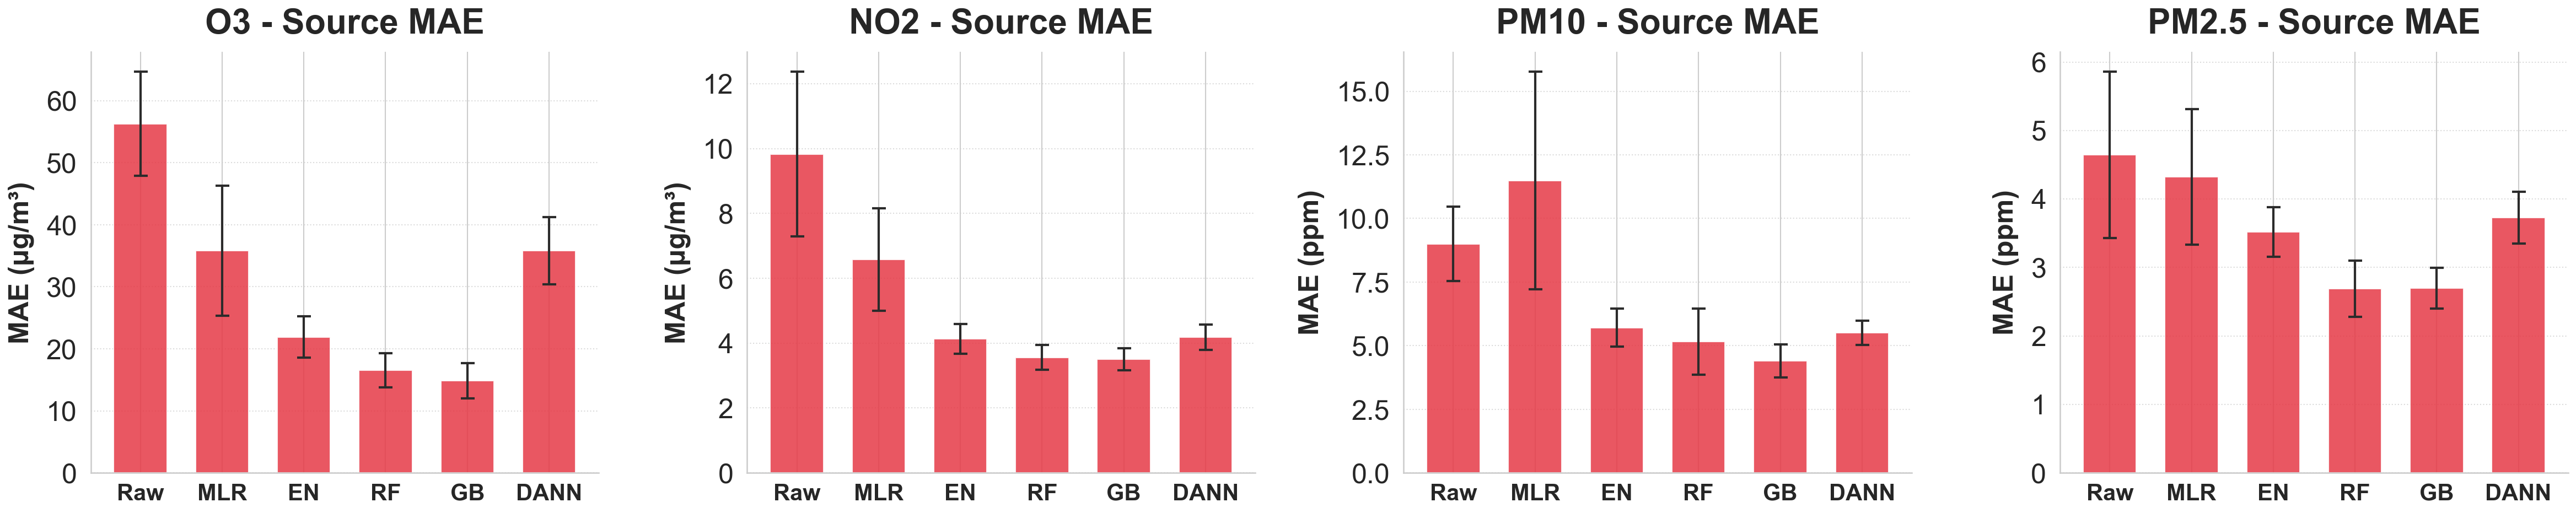

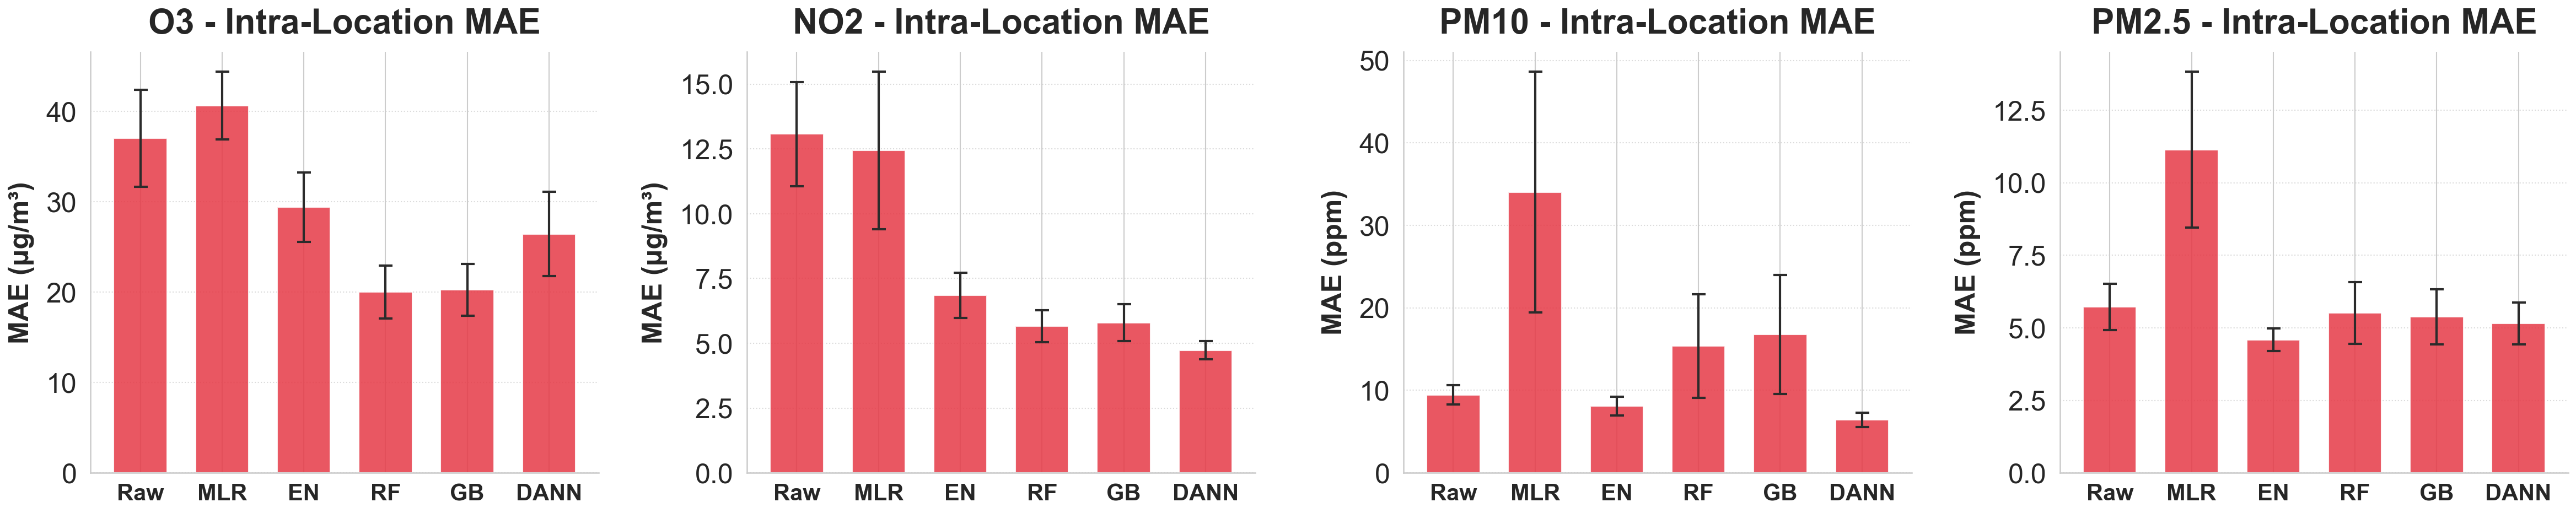

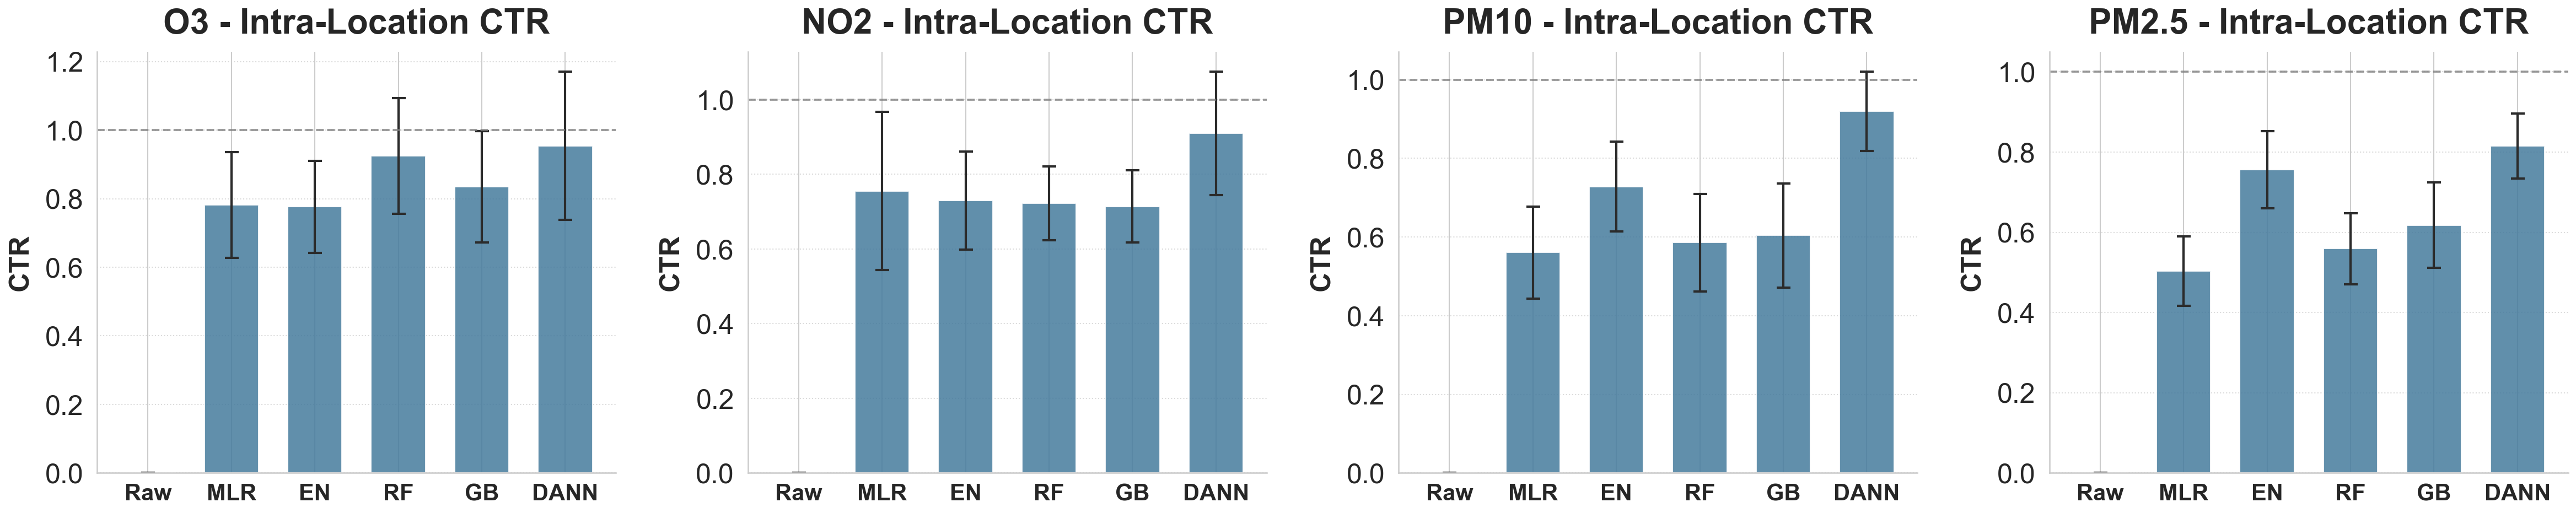

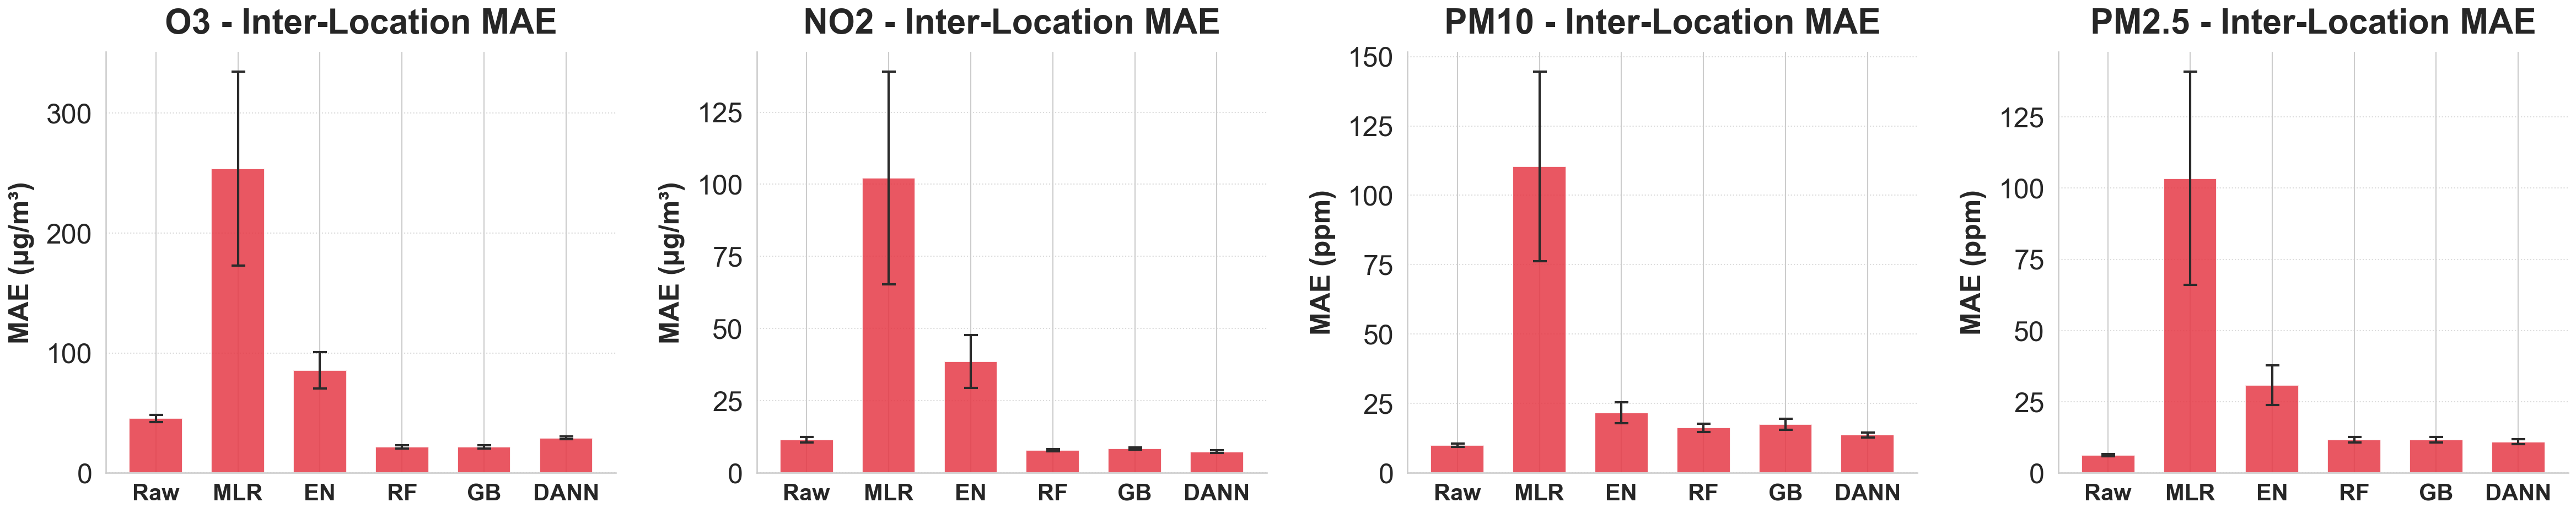

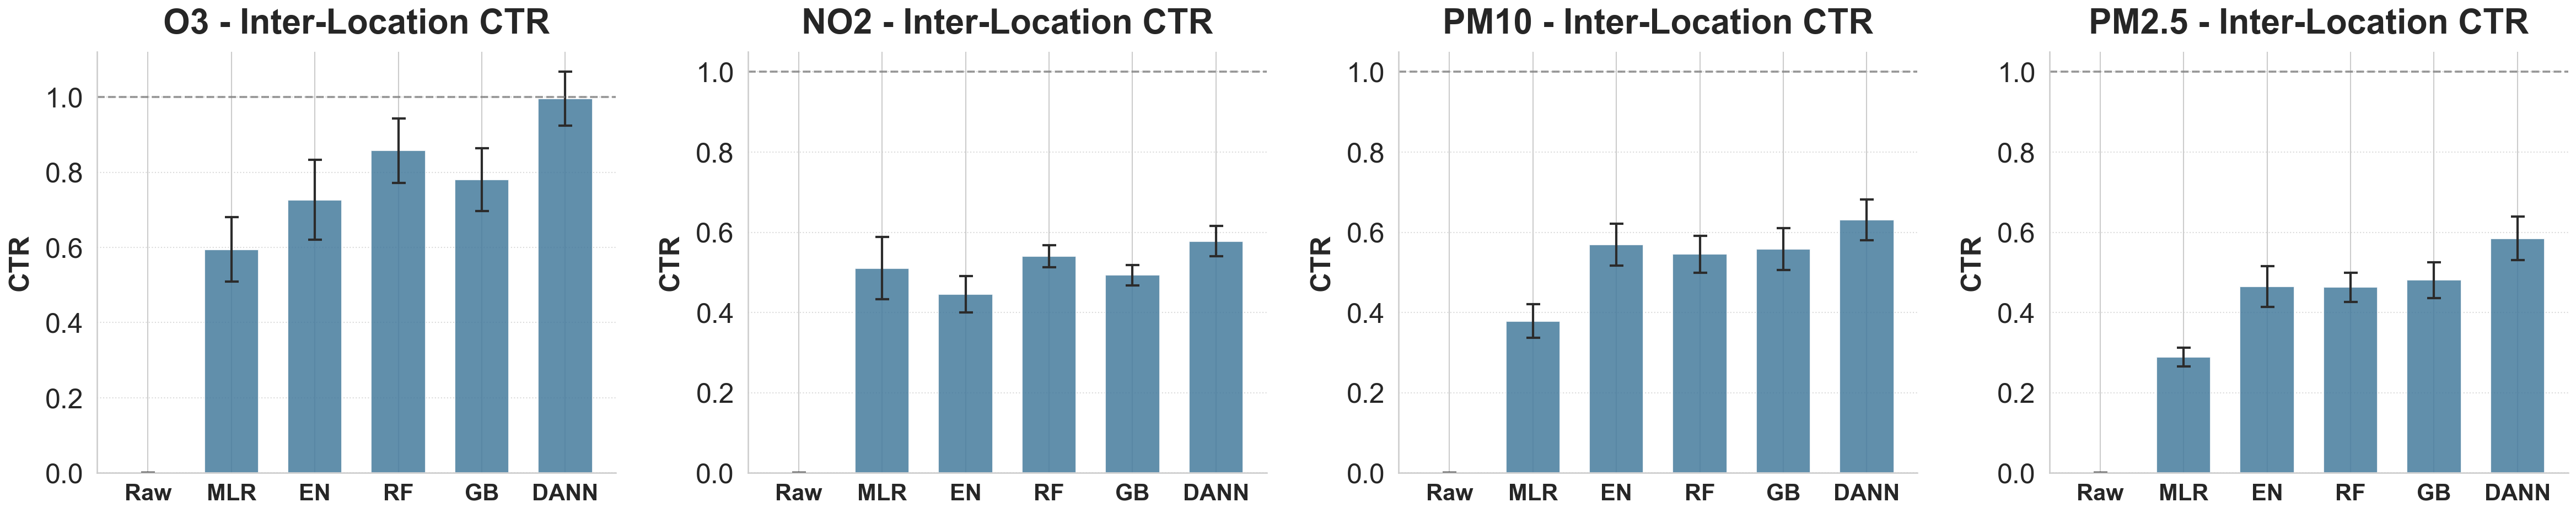

In [41]:
# VISUALIZATION 

# Load the saved results if available - can look at the graphs without any training
results_manager = joblib.load('../results/results_manager.pkl')

all_models = ['Raw', 'Linear', 'ElasticNet', 'RandomForest', 'GradientBoosting', 'DANN']
# all_models = ['Raw', 'ElasticNet', 'RandomForest', 'GradientBoosting', 'DANN']
all_sensors = ['O3', 'NO2', 'PM10', 'PM2.5']
target_device1 = 'Halle_2'
target_device2 = 'Ukkel_2'

# plot time series data for a single model (high resolution)
# plot_line_raw_ref(results_manager, train_device, all_sensors, 'GradientBoosting')

# plot time series data for all models
# plot_unified_evaluation(results_manager, train_device, all_sensors, all_models)

# prints metrics for source mae and targets mae + ctr
# print_transfer_metrics_tables(results_manager, train_device, device_data, all_sensors, all_models)

# generates bar graphs for source mae and targets mae + ctr
# plot_source_and_transfer_grids(results_manager, train_device, target_device1, target_device2, all_sensors, all_models)

# same as above but aggregates across all devices
plot_aggregated_transfer_grids(results_manager, all_sensors, all_models)

In [33]:
# save all the results
# joblib.dump(results_manager, '../results/results_manager.pkl')

# calibrated_test_files = export_source_test_csvs(
#     results_manager=results_manager,
#     device_data=device_data,
#     output_dir='../other/CalibratedSourceData'
# )